In [1]:
import torch
from torch import nn
from torch.utils.data import DataLoader, random_split, Subset

import torchvision
from torchvision import datasets, transforms

import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

print("Bibliothèques importées avec succès.")

Bibliothèques importées avec succès.


In [2]:
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
print("Device utilisé :", device)

Device utilisé : mps


In [3]:
torch.manual_seed(42)
np.random.seed(42)

print("Seed fixé avec succès.")

Seed fixé avec succès.


In [4]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

train_full = datasets.FashionMNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_full = datasets.FashionMNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

print("Train complet :", len(train_full))
print("Test complet :", len(test_full))

100%|█████████████████████████████████████████████████████████████████████████████| 26.4M/26.4M [00:07<00:00, 3.53MB/s]
100%|██████████████████████████████████████████████████████████████████████████████| 29.5k/29.5k [00:00<00:00, 646kB/s]
100%|█████████████████████████████████████████████████████████████████████████████| 4.42M/4.42M [00:01<00:00, 4.33MB/s]
100%|█████████████████████████████████████████████████████████████████████████████| 5.15k/5.15k [00:00<00:00, 7.55MB/s]

Train complet : 60000
Test complet : 10000


In [5]:
train_subset = Subset(train_full, range(10000))
test_subset = Subset(test_full, range(2000))

train_size = 8000
val_size = 2000

train_dataset, val_dataset = random_split(
    train_subset,
    [train_size, val_size],
    generator=torch.Generator().manual_seed(42)
)

test_dataset = test_subset

print("Train :", len(train_dataset))
print("Validation :", len(val_dataset))
print("Test :", len(test_dataset))

Train : 8000
Validation : 2000
Test : 2000


In [6]:
batch_size = 64

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=0)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=0)

print("DataLoader créés avec succès.")

DataLoader créés avec succès.


In [7]:
class_names = train_full.classes
print(class_names)

['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


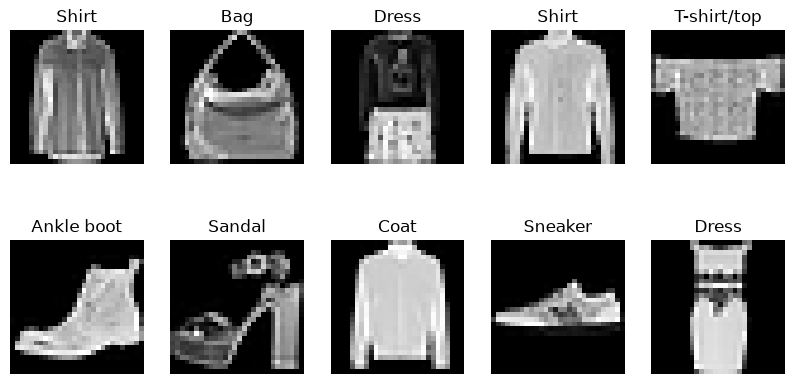

In [8]:
images, labels = next(iter(train_loader))

plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    img = images[i].squeeze()
    plt.imshow(img, cmap="gray")
    plt.title(class_names[labels[i]])
    plt.axis("off")

plt.show()

In [9]:
def corr2d(X, K):
    """
    X : image 2D
    K : noyau 2D
    Retourne la corrélation croisée 2D
    """
    h, w = K.shape
    Y = torch.zeros((X.shape[0] - h + 1, X.shape[1] - w + 1))
    
    for i in range(Y.shape[0]):
        for j in range(Y.shape[1]):
            region = X[i:i+h, j:j+w]
            Y[i, j] = (region * K).sum()
    
    return Y

In [10]:
X_exemple = torch.tensor([
    [0., 1., 2.],
    [3., 4., 5.],
    [6., 7., 8.]
])

K_exemple = torch.tensor([
    [0., 1.],
    [2., 3.]
])

Y_exemple = corr2d(X_exemple, K_exemple)
print(Y_exemple)

tensor([[19., 25.],
        [37., 43.]])


In [11]:
def pool2d(X, pool_size, mode="max"):
    """
    X : image 2D
    pool_size : taille de la fenêtre, exemple (2, 2)
    mode : max ou avg
    """
    p_h, p_w = pool_size
    Y = torch.zeros((X.shape[0] - p_h + 1, X.shape[1] - p_w + 1))
    
    for i in range(Y.shape[0]):
        for j in range(Y.shape[1]):
            region = X[i:i+p_h, j:j+p_w]
            
            if mode == "max":
                Y[i, j] = region.max()
            elif mode == "avg":
                Y[i, j] = region.mean()
            else:
                raise ValueError("mode doit être 'max' ou 'avg'")
    
    return Y

In [12]:
X_pool = torch.tensor([
    [0., 1., 2.],
    [3., 4., 5.],
    [6., 7., 8.]
])

print("Max pooling :")
print(pool2d(X_pool, (2, 2), mode="max"))

print("Average pooling :")
print(pool2d(X_pool, (2, 2), mode="avg"))

Max pooling :
tensor([[4., 5.],
        [7., 8.]])
Average pooling :
tensor([[2., 3.],
        [5., 6.]])


In [13]:
class CNN_LeNet(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        
        self.features = nn.Sequential(
            nn.Conv2d(1, 6, kernel_size=5, padding=2),
            nn.ReLU(),
            nn.AvgPool2d(kernel_size=2, stride=2),
            
            nn.Conv2d(6, 16, kernel_size=5),
            nn.ReLU(),
            nn.AvgPool2d(kernel_size=2, stride=2)
        )
        
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(16 * 5 * 5, 120),
            nn.ReLU(),
            nn.Linear(120, 84),
            nn.ReLU(),
            nn.Linear(84, num_classes)
        )
        
    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

In [14]:
cnn_model = CNN_LeNet(num_classes=10).to(device)

print(cnn_model)

CNN_LeNet(
  (features): Sequential(
    (0): Conv2d(1, 6, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (1): ReLU()
    (2): AvgPool2d(kernel_size=2, stride=2, padding=0)
    (3): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
    (4): ReLU()
    (5): AvgPool2d(kernel_size=2, stride=2, padding=0)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=400, out_features=120, bias=True)
    (2): ReLU()
    (3): Linear(in_features=120, out_features=84, bias=True)
    (4): ReLU()
    (5): Linear(in_features=84, out_features=10, bias=True)
  )
)


In [15]:
X_batch, y_batch = next(iter(train_loader))
X_batch = X_batch.to(device)

x = X_batch[:1]

print("Entrée :", x.shape)

for layer in cnn_model.features:
    x = layer(x)
    print(layer.__class__.__name__, ":", x.shape)

Entrée : torch.Size([1, 1, 28, 28])
Conv2d : torch.Size([1, 6, 28, 28])
ReLU : torch.Size([1, 6, 28, 28])
AvgPool2d : torch.Size([1, 6, 14, 14])
Conv2d : torch.Size([1, 16, 10, 10])
ReLU : torch.Size([1, 16, 10, 10])
AvgPool2d : torch.Size([1, 16, 5, 5])


In [16]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(cnn_model.parameters(), lr=0.001)

print("Loss et optimiseur créés.")

Loss et optimiseur créés.


In [17]:
def train_one_epoch_cnn(model, train_loader, criterion, optimizer, device):
    model.train()
    total_loss = 0
    
    for X_batch, y_batch in train_loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)
        
        optimizer.zero_grad()
        
        outputs = model(X_batch)
        loss = criterion(outputs, y_batch)
        
        loss.backward()
        optimizer.step()
        
        total_loss += loss.item()
    
    return total_loss / len(train_loader)


def evaluate_cnn(model, data_loader, criterion, device):
    model.eval()
    total_loss = 0
    all_preds = []
    all_labels = []
    
    with torch.no_grad():
        for X_batch, y_batch in data_loader:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)
            
            outputs = model(X_batch)
            loss = criterion(outputs, y_batch)
            
            total_loss += loss.item()
            
            preds = torch.argmax(outputs, dim=1)
            
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(y_batch.cpu().numpy())
    
    acc = accuracy_score(all_labels, all_preds)
    
    return total_loss / len(data_loader), acc

In [18]:
num_epochs = 10

train_losses_cnn = []
val_losses_cnn = []
train_accuracies_cnn = []
val_accuracies_cnn = []

for epoch in range(num_epochs):
    train_loss = train_one_epoch_cnn(cnn_model, train_loader, criterion, optimizer, device)
    
    train_loss_eval, train_acc = evaluate_cnn(cnn_model, train_loader, criterion, device)
    val_loss, val_acc = evaluate_cnn(cnn_model, val_loader, criterion, device)
    
    train_losses_cnn.append(train_loss)
    val_losses_cnn.append(val_loss)
    train_accuracies_cnn.append(train_acc)
    val_accuracies_cnn.append(val_acc)
    
    print(f"Epoch [{epoch+1}/{num_epochs}] | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}")

Epoch [1/10] | Train Loss: 1.1229 | Val Loss: 0.7417 | Val Acc: 0.7245
Epoch [2/10] | Train Loss: 0.7080 | Val Loss: 0.6924 | Val Acc: 0.7225
Epoch [3/10] | Train Loss: 0.6284 | Val Loss: 0.6124 | Val Acc: 0.7540
Epoch [4/10] | Train Loss: 0.5731 | Val Loss: 0.5414 | Val Acc: 0.8015
Epoch [5/10] | Train Loss: 0.5326 | Val Loss: 0.5320 | Val Acc: 0.7965
Epoch [6/10] | Train Loss: 0.4960 | Val Loss: 0.4870 | Val Acc: 0.8185
Epoch [7/10] | Train Loss: 0.4637 | Val Loss: 0.4849 | Val Acc: 0.8250
Epoch [8/10] | Train Loss: 0.4390 | Val Loss: 0.4680 | Val Acc: 0.8245
Epoch [9/10] | Train Loss: 0.4191 | Val Loss: 0.4696 | Val Acc: 0.8275
Epoch [10/10] | Train Loss: 0.3922 | Val Loss: 0.4474 | Val Acc: 0.8385


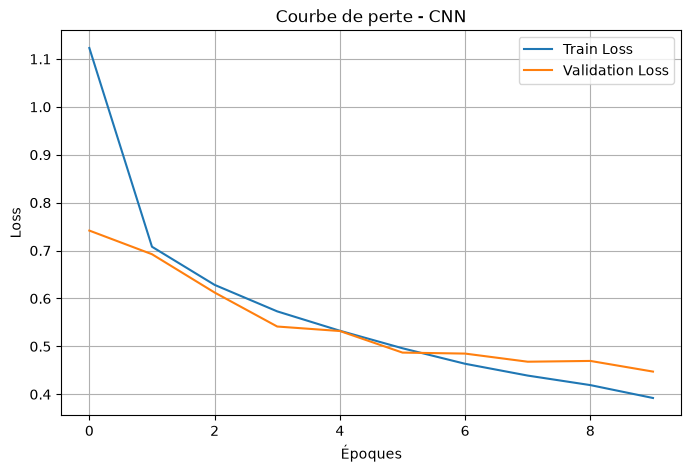

In [19]:
plt.figure(figsize=(8,5))
plt.plot(train_losses_cnn, label="Train Loss")
plt.plot(val_losses_cnn, label="Validation Loss")
plt.xlabel("Époques")
plt.ylabel("Loss")
plt.title("Courbe de perte - CNN")
plt.legend()
plt.grid(True)
plt.show()

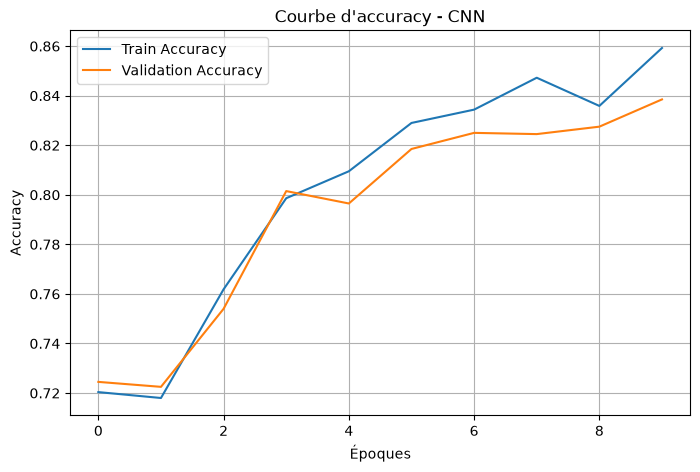

In [20]:
plt.figure(figsize=(8,5))
plt.plot(train_accuracies_cnn, label="Train Accuracy")
plt.plot(val_accuracies_cnn, label="Validation Accuracy")
plt.xlabel("Époques")
plt.ylabel("Accuracy")
plt.title("Courbe d'accuracy - CNN")
plt.legend()
plt.grid(True)
plt.show()

In [21]:
cnn_model.eval()

all_preds_cnn = []
all_labels_cnn = []

with torch.no_grad():
    for X_batch, y_batch in test_loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)
        
        outputs = cnn_model(X_batch)
        preds = torch.argmax(outputs, dim=1)
        
        all_preds_cnn.extend(preds.cpu().numpy())
        all_labels_cnn.extend(y_batch.cpu().numpy())

accuracy_cnn = accuracy_score(all_labels_cnn, all_preds_cnn)
precision_cnn = precision_score(all_labels_cnn, all_preds_cnn, average="macro")
recall_cnn = recall_score(all_labels_cnn, all_preds_cnn, average="macro")
f1_cnn = f1_score(all_labels_cnn, all_preds_cnn, average="macro")

print("Résultats finaux du CNN sur le test set")
print("Accuracy :", round(accuracy_cnn, 4))
print("Precision macro :", round(precision_cnn, 4))
print("Recall macro :", round(recall_cnn, 4))
print("F1-score macro :", round(f1_cnn, 4))

Résultats finaux du CNN sur le test set
Accuracy : 0.8375
Precision macro : 0.8389
Recall macro : 0.8397
F1-score macro : 0.8358


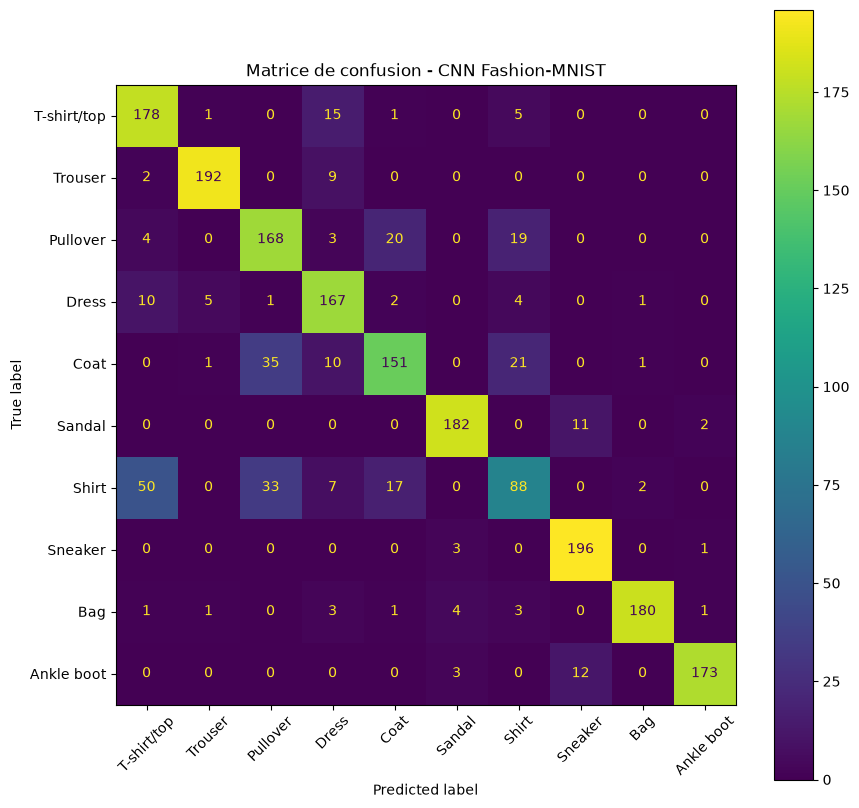

In [22]:
cm_cnn = confusion_matrix(all_labels_cnn, all_preds_cnn)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_cnn,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(10, 10))
disp.plot(ax=ax, xticks_rotation=45)
plt.title("Matrice de confusion - CNN Fashion-MNIST")
plt.show()

In [23]:
torch.save(cnn_model.state_dict(), "best_cnn_fashion_mnist.pth")
print("Modèle CNN sauvegardé avec succès.")

Modèle CNN sauvegardé avec succès.


### Analyse des résultats du CNN

Le modèle CNN inspiré de LeNet a été entraîné sur le dataset Fashion-MNIST. Ce dataset contient des images en niveaux de gris de taille 28×28 réparties en 10 classes de vêtements.

Les résultats montrent que le CNN atteint une accuracy de validation de 0.8385 après 10 époques. La perte d’entraînement diminue progressivement, ce qui indique que le modèle apprend correctement les motifs visuels présents dans les images. La perte de validation diminue également, ce qui montre une bonne capacité de généralisation sur les données non vues.

Le CNN est plus adapté aux images qu’un MLP, car il conserve la structure spatiale des pixels. Les couches convolutionnelles permettent d’extraire localement des motifs comme les contours, les textures et les formes. Le pooling réduit la dimension des cartes de caractéristiques tout en conservant les informations importantes.

Les résultats peuvent encore être améliorés en augmentant le nombre d’époques, en utilisant un modèle plus profond, en remplaçant l’average pooling par du max pooling ou en ajoutant de la normalisation batch.

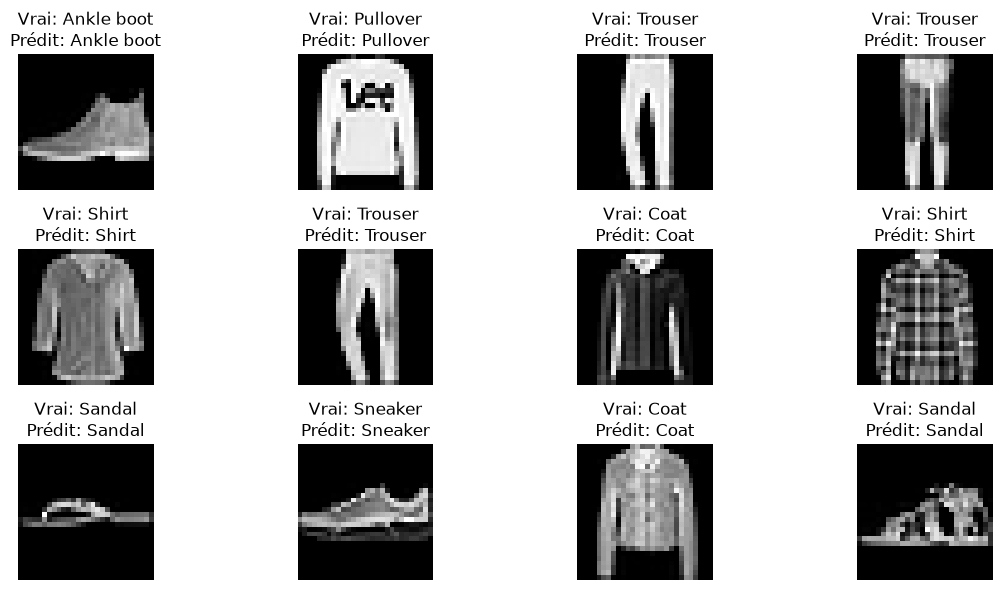

In [24]:
cnn_model.eval()

images, labels = next(iter(test_loader))
images_device = images.to(device)

with torch.no_grad():
    outputs = cnn_model(images_device)
    preds = torch.argmax(outputs, dim=1).cpu()

plt.figure(figsize=(12, 6))

for i in range(12):
    plt.subplot(3, 4, i + 1)
    img = images[i].squeeze()
    plt.imshow(img, cmap="gray")
    
    true_label = class_names[labels[i]]
    pred_label = class_names[preds[i]]
    
    plt.title(f"Vrai: {true_label}\nPrédit: {pred_label}")
    plt.axis("off")

plt.tight_layout()
plt.show()

### Résultats finaux du CNN sur le test set

Le modèle CNN inspiré de LeNet a été évalué sur le test set de Fashion-MNIST. Les résultats obtenus sont les suivants :

- Accuracy : 0.8375
- Precision macro : 0.8389
- Recall macro : 0.8397
- F1-score macro : 0.8358

Ces résultats montrent que le CNN parvient à reconnaître correctement une grande partie des images de vêtements. L’accuracy de 0.8375 indique que le modèle classe correctement environ 83,75 % des images du test set.

Le F1-score macro de 0.8358 montre que les performances sont globalement équilibrées entre les différentes classes. L’utilisation de la moyenne macro est pertinente car elle donne la même importance à chaque classe.

Le CNN est adapté à ce type de données, car il conserve la structure spatiale de l’image. Contrairement à un MLP qui transforme l’image en vecteur, le CNN exploite les relations locales entre pixels grâce aux filtres convolutionnels. Les couches de pooling permettent ensuite de réduire progressivement la dimension tout en conservant les informations importantes.

Les résultats peuvent être améliorés en augmentant le nombre d’époques, en utilisant davantage de données d’entraînement, en ajoutant des couches convolutionnelles, ou encore en testant le max-pooling à la place de l’average-pooling.

In [25]:
class MLP_Image(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            
            nn.Linear(128, num_classes)
        )
        
    def forward(self, x):
        return self.net(x)

In [26]:
mlp_image = MLP_Image(num_classes=10).to(device)

criterion_mlp_img = nn.CrossEntropyLoss()
optimizer_mlp_img = torch.optim.Adam(mlp_image.parameters(), lr=0.001)

print(mlp_image)

MLP_Image(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=256, out_features=128, bias=True)
    (5): ReLU()
    (6): Dropout(p=0.3, inplace=False)
    (7): Linear(in_features=128, out_features=10, bias=True)
  )
)


In [27]:
num_epochs_mlp = 10

train_losses_mlp_img = []
val_losses_mlp_img = []
train_accuracies_mlp_img = []
val_accuracies_mlp_img = []

for epoch in range(num_epochs_mlp):
    train_loss = train_one_epoch_cnn(
        mlp_image, train_loader, criterion_mlp_img, optimizer_mlp_img, device
    )
    
    train_loss_eval, train_acc = evaluate_cnn(
        mlp_image, train_loader, criterion_mlp_img, device
    )
    
    val_loss, val_acc = evaluate_cnn(
        mlp_image, val_loader, criterion_mlp_img, device
    )
    
    train_losses_mlp_img.append(train_loss)
    val_losses_mlp_img.append(val_loss)
    train_accuracies_mlp_img.append(train_acc)
    val_accuracies_mlp_img.append(val_acc)
    
    print(f"Epoch [{epoch+1}/{num_epochs_mlp}] | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}")

Epoch [1/10] | Train Loss: 0.9048 | Val Loss: 0.5718 | Val Acc: 0.7780
Epoch [2/10] | Train Loss: 0.5901 | Val Loss: 0.5098 | Val Acc: 0.8110
Epoch [3/10] | Train Loss: 0.5345 | Val Loss: 0.4953 | Val Acc: 0.8190
Epoch [4/10] | Train Loss: 0.4796 | Val Loss: 0.4583 | Val Acc: 0.8370
Epoch [5/10] | Train Loss: 0.4588 | Val Loss: 0.4876 | Val Acc: 0.8230
Epoch [6/10] | Train Loss: 0.4185 | Val Loss: 0.4447 | Val Acc: 0.8390
Epoch [7/10] | Train Loss: 0.4013 | Val Loss: 0.5199 | Val Acc: 0.8145
Epoch [8/10] | Train Loss: 0.3904 | Val Loss: 0.4275 | Val Acc: 0.8480
Epoch [9/10] | Train Loss: 0.3758 | Val Loss: 0.4334 | Val Acc: 0.8470
Epoch [10/10] | Train Loss: 0.3600 | Val Loss: 0.4140 | Val Acc: 0.8530


In [28]:
mlp_image.eval()

all_preds_mlp_img = []
all_labels_mlp_img = []

with torch.no_grad():
    for X_batch, y_batch in test_loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)
        
        outputs = mlp_image(X_batch)
        preds = torch.argmax(outputs, dim=1)
        
        all_preds_mlp_img.extend(preds.cpu().numpy())
        all_labels_mlp_img.extend(y_batch.cpu().numpy())

accuracy_mlp_img = accuracy_score(all_labels_mlp_img, all_preds_mlp_img)
precision_mlp_img = precision_score(all_labels_mlp_img, all_preds_mlp_img, average="macro")
recall_mlp_img = recall_score(all_labels_mlp_img, all_preds_mlp_img, average="macro")
f1_mlp_img = f1_score(all_labels_mlp_img, all_preds_mlp_img, average="macro")

print("Résultats finaux du MLP image sur le test set")
print("Accuracy :", round(accuracy_mlp_img, 4))
print("Precision macro :", round(precision_mlp_img, 4))
print("Recall macro :", round(recall_mlp_img, 4))
print("F1-score macro :", round(f1_mlp_img, 4))

Résultats finaux du MLP image sur le test set
Accuracy : 0.8615
Precision macro : 0.8695
Recall macro : 0.8634
F1-score macro : 0.865


In [29]:
comparison_results = pd.DataFrame({
    "Modèle": ["MLP image", "CNN LeNet"],
    "Accuracy": [accuracy_mlp_img, accuracy_cnn],
    "Precision macro": [precision_mlp_img, precision_cnn],
    "Recall macro": [recall_mlp_img, recall_cnn],
    "F1-score macro": [f1_mlp_img, f1_cnn]
})

comparison_results

NameError: name 'pd' is not defined

In [30]:
import pandas as pd

print("Pandas importé avec succès.")

Pandas importé avec succès.


In [31]:
comparison_results = pd.DataFrame({
    "Modèle": ["MLP image", "CNN LeNet"],
    "Accuracy": [accuracy_mlp_img, accuracy_cnn],
    "Precision macro": [precision_mlp_img, precision_cnn],
    "Recall macro": [recall_mlp_img, recall_cnn],
    "F1-score macro": [f1_mlp_img, f1_cnn]
})

comparison_results

,Modèle,Accuracy,Precision macro,Recall macro,F1-score macro
0,MLP image,0.8615,0.869530,0.863437,0.864998
1,CNN LeNet,0.8375,0.838935,0.839739,0.835810


In [32]:
class CNN_Ameliore(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d((1, 1))
        )
        
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, num_classes)
        )
        
    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

In [33]:
cnn_ameliore = CNN_Ameliore(num_classes=10).to(device)

criterion_cnn2 = nn.CrossEntropyLoss()
optimizer_cnn2 = torch.optim.Adam(cnn_ameliore.parameters(), lr=0.001)

num_epochs_cnn2 = 10

train_losses_cnn2 = []
val_losses_cnn2 = []
train_accuracies_cnn2 = []
val_accuracies_cnn2 = []

for epoch in range(num_epochs_cnn2):
    train_loss = train_one_epoch_cnn(
        cnn_ameliore, train_loader, criterion_cnn2, optimizer_cnn2, device
    )
    
    train_loss_eval, train_acc = evaluate_cnn(
        cnn_ameliore, train_loader, criterion_cnn2, device
    )
    
    val_loss, val_acc = evaluate_cnn(
        cnn_ameliore, val_loader, criterion_cnn2, device
    )
    
    train_losses_cnn2.append(train_loss)
    val_losses_cnn2.append(val_loss)
    train_accuracies_cnn2.append(train_acc)
    val_accuracies_cnn2.append(val_acc)
    
    print(f"Epoch [{epoch+1}/{num_epochs_cnn2}] | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}")

Epoch [1/10] | Train Loss: 1.3152 | Val Loss: 0.7796 | Val Acc: 0.7335
Epoch [2/10] | Train Loss: 0.7299 | Val Loss: 0.8198 | Val Acc: 0.6950
Epoch [3/10] | Train Loss: 0.6056 | Val Loss: 0.5766 | Val Acc: 0.7945
Epoch [4/10] | Train Loss: 0.5271 | Val Loss: 0.8290 | Val Acc: 0.7345
Epoch [5/10] | Train Loss: 0.4834 | Val Loss: 0.6224 | Val Acc: 0.7885
Epoch [6/10] | Train Loss: 0.4368 | Val Loss: 0.7164 | Val Acc: 0.7475
Epoch [7/10] | Train Loss: 0.4113 | Val Loss: 0.5627 | Val Acc: 0.8120
Epoch [8/10] | Train Loss: 0.3803 | Val Loss: 0.5671 | Val Acc: 0.8040
Epoch [9/10] | Train Loss: 0.3621 | Val Loss: 0.4095 | Val Acc: 0.8655
Epoch [10/10] | Train Loss: 0.3475 | Val Loss: 0.4670 | Val Acc: 0.8325


In [34]:
cnn_ameliore.eval()

all_preds_cnn2 = []
all_labels_cnn2 = []

with torch.no_grad():
    for X_batch, y_batch in test_loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)
        
        outputs = cnn_ameliore(X_batch)
        preds = torch.argmax(outputs, dim=1)
        
        all_preds_cnn2.extend(preds.cpu().numpy())
        all_labels_cnn2.extend(y_batch.cpu().numpy())

accuracy_cnn2 = accuracy_score(all_labels_cnn2, all_preds_cnn2)
precision_cnn2 = precision_score(all_labels_cnn2, all_preds_cnn2, average="macro")
recall_cnn2 = recall_score(all_labels_cnn2, all_preds_cnn2, average="macro")
f1_cnn2 = f1_score(all_labels_cnn2, all_preds_cnn2, average="macro")

print("Résultats du CNN amélioré")
print("Accuracy :", round(accuracy_cnn2, 4))
print("Precision macro :", round(precision_cnn2, 4))
print("Recall macro :", round(recall_cnn2, 4))
print("F1-score macro :", round(f1_cnn2, 4))

Résultats du CNN amélioré
Accuracy : 0.832
Precision macro : 0.8499
Recall macro : 0.8324
F1-score macro : 0.8309


In [35]:
comparison_results_final = pd.DataFrame({
    "Modèle": ["MLP image", "CNN LeNet", "CNN amélioré"],
    "Accuracy": [accuracy_mlp_img, accuracy_cnn, accuracy_cnn2],
    "Precision macro": [precision_mlp_img, precision_cnn, precision_cnn2],
    "Recall macro": [recall_mlp_img, recall_cnn, recall_cnn2],
    "F1-score macro": [f1_mlp_img, f1_cnn, f1_cnn2]
})

comparison_results_final

,Modèle,Accuracy,Precision macro,Recall macro,F1-score macro
0,MLP image,0.8615,0.869530,0.863437,0.864998
1,CNN LeNet,0.8375,0.838935,0.839739,0.835810
2,CNN amélioré,0.8320,0.849926,0.832447,0.830851


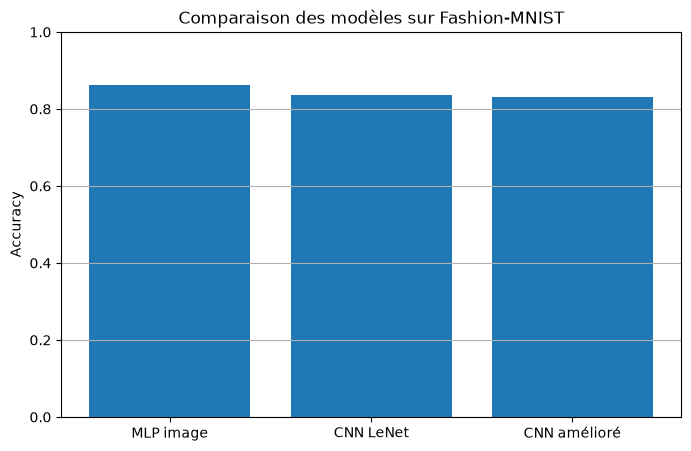

In [36]:
plt.figure(figsize=(8,5))
plt.bar(comparison_results_final["Modèle"], comparison_results_final["Accuracy"])
plt.ylabel("Accuracy")
plt.title("Comparaison des modèles sur Fashion-MNIST")
plt.ylim(0, 1)
plt.grid(axis="y")
plt.show()

### Comparaison finale des modèles sur Fashion-MNIST

Trois modèles ont été comparés sur le dataset Fashion-MNIST : un MLP appliqué aux images aplaties, un CNN inspiré de LeNet et un CNN plus profond avec Batch Normalization et MaxPooling.

Les résultats obtenus sont les suivants :

| Modèle       | Accuracy | Precision macro | Recall macro | F1-score macro |
| ------------ | -------: | --------------: | -----------: | -------------: |
| MLP image    |   0.8615 |          0.8695 |       0.8634 |         0.8650 |
| CNN LeNet    |   0.8375 |          0.8389 |       0.8397 |         0.8358 |
| CNN amélioré |   0.8320 |          0.8499 |       0.8324 |         0.8309 |

Dans cette expérimentation, le MLP obtient la meilleure accuracy. Ce résultat peut sembler surprenant, car les CNN sont théoriquement plus adaptés aux images. Toutefois, il s’explique par plusieurs éléments méthodologiques : le CNN a été entraîné sur un sous-ensemble réduit de Fashion-MNIST, avec seulement 10 époques, et sans recherche approfondie des hyperparamètres.

Le CNN LeNet reste pertinent, car il conserve la structure spatiale de l’image grâce aux couches convolutionnelles. Contrairement au MLP, qui transforme l’image 28×28 en un vecteur de 784 valeurs, le CNN applique des filtres locaux capables de détecter progressivement des motifs visuels tels que les contours, les textures et les formes.

Le CNN amélioré n’a pas dépassé le CNN LeNet dans cette expérience. Cela montre qu’augmenter la profondeur ou ajouter Batch Normalization ne garantit pas automatiquement une amélioration. Les performances dépendent aussi du nombre d’époques, de la taille du dataset, du learning rate, du choix du pooling et de la régularisation.

Ainsi, l’analyse expérimentale confirme que le choix d’une architecture doit être justifié à la fois par la théorie et par les résultats obtenus. Même si le MLP donne ici un meilleur score, le CNN reste conceptuellement plus adapté aux images grâce à son biais inductif spatial.


In [37]:
torch.save(cnn_model.state_dict(), "cnn_lenet_fashion_mnist.pth")
torch.save(cnn_ameliore.state_dict(), "cnn_ameliore_fashion_mnist.pth")

print("Modèles CNN sauvegardés avec succès.")

Modèles CNN sauvegardés avec succès.


### Réponse à la question de synthèse – Partie II

Un CNN est théoriquement plus pertinent qu’un MLP pour une tâche de classification d’images, car il exploite directement la structure spatiale des pixels. Alors qu’un MLP aplatit l’image en un vecteur et perd l’organisation 2D, un CNN conserve cette structure et applique des filtres locaux partagés sur l’ensemble de l’image.

Les convolutions permettent d’extraire progressivement des motifs visuels simples puis complexes. Les premières couches peuvent détecter des contours ou des contrastes, tandis que les couches plus profondes peuvent combiner ces informations pour reconnaître des formes plus globales. Le pooling réduit la dimension des cartes de caractéristiques et diminue le coût de calcul, tout en conservant les activations importantes.

Les choix architecturaux influencent directement les performances. Le padding permet de conserver la taille spatiale et d’éviter une perte excessive d’information sur les bords. Le stride contrôle la vitesse de réduction de la résolution. Le type de pooling influence la manière dont les informations locales sont résumées : le max-pooling retient les activations les plus fortes, tandis que l’average-pooling calcule une moyenne locale. Enfin, le nombre de filtres et la profondeur du réseau déterminent la capacité du modèle à apprendre des représentations visuelles riches.

Dans notre expérience, le MLP obtient une accuracy supérieure au CNN. Ce résultat ne contredit pas la pertinence théorique des CNN, mais montre que la performance dépend fortement des conditions expérimentales : taille du dataset utilisé, nombre d’époques, architecture choisie, régularisation et hyperparamètres. Avec davantage de données, un entraînement plus long et une architecture mieux optimisée, le CNN pourrait obtenir de meilleures performances.


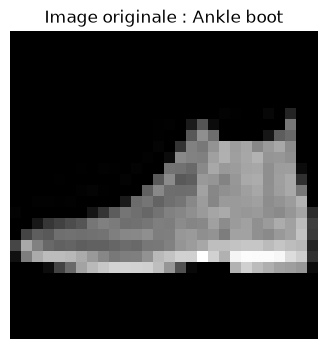

In [38]:
images, labels = next(iter(test_loader))

image = images[0]
label = labels[0]

plt.figure(figsize=(4,4))
plt.imshow(image.squeeze(), cmap="gray")
plt.title(f"Image originale : {class_names[label]}")
plt.axis("off")
plt.show()

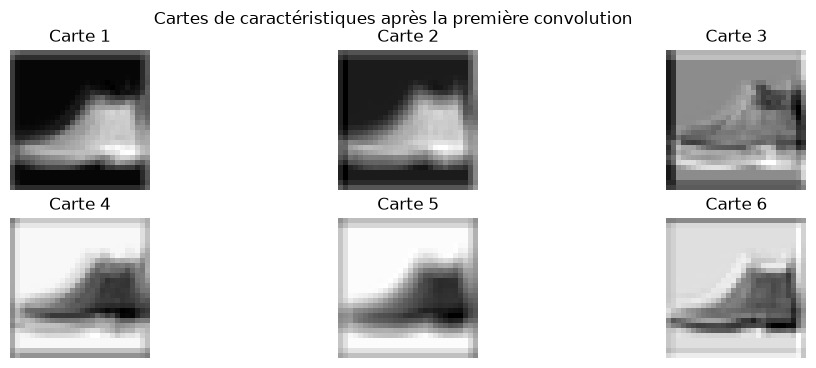

In [39]:
cnn_model.eval()

image_device = image.unsqueeze(0).to(device)

with torch.no_grad():
    feature_maps = cnn_model.features[0](image_device)

feature_maps = feature_maps.cpu().squeeze()

plt.figure(figsize=(12, 4))

for i in range(6):
    plt.subplot(2, 3, i + 1)
    plt.imshow(feature_maps[i], cmap="gray")
    plt.title(f"Carte {i+1}")
    plt.axis("off")

plt.suptitle("Cartes de caractéristiques après la première convolution")
plt.show()

### Visualisation des cartes de caractéristiques

La visualisation des cartes de caractéristiques permet d’observer les activations produites par les filtres convolutionnels après la première couche du CNN. Chaque carte correspond à la réponse d’un filtre appliqué localement sur l’image d’entrée.

Les premières cartes de caractéristiques mettent généralement en évidence des motifs simples comme les contours, les contrastes, certaines zones sombres ou claires et des formes locales. Cela confirme que le CNN ne traite pas l’image comme un simple vecteur, mais comme une structure spatiale.

Cette visualisation montre l’intérêt des couches convolutionnelles : elles apprennent automatiquement des représentations intermédiaires utiles pour la classification. Les couches profondes combinent ensuite ces motifs simples pour produire une décision finale.

In [40]:
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import random
import math
from collections import Counter

print("Bibliothèques importées avec succès.")

Bibliothèques importées avec succès.
